# Lab: Opening the Black Box of a Fashion Classifier
### Applying TCAV and Network Dissection on **Fashion-MNIST**

**Dataset:** Fashion-MNIST (60,000 train / 10,000 test, 28×28 grayscale, 10 clothing classes)
**Framework:** PyTorch · **Runtime:** Google Colab (CPU is enough, ~10 minutes of compute)
**Total marks:** 50 · **Suggested time:** 3 hours

---

## Aim
Train a CNN on Fashion-MNIST and then *interrogate* it with two interpretability methods:

| Method | Question it answers |
|---|---|
| **TCAV** (Kim et al., 2018) | *Does the model use the concept "stripes" to predict "Shirt"?* (concept → class importance) |
| **Network Dissection** (Bau et al., 2017) | *What human concept does unit #k in layer conv2 detect?* (unit → concept alignment) |

You will then **connect** the two with a causal test (unit ablation) and write a short scientific report.

## Learning outcomes
After this lab you can:
1. Train a CNN and extract intermediate activations at chosen layers.
2. Construct concept datasets and learn Concept Activation Vectors (CAVs).
3. Compute TCAV scores with a statistical significance test.
4. Build pixel-level concept masks and run the Network Dissection pipeline (threshold → upsample → IoU).
5. Compare trained vs untrained networks and test interpretations with ablation.
6. Critically discuss confounds and limitations of both methods.

## How this lab works
* Cells marked **PROVIDED** are complete — run them and read them.
* Cells marked **YOUR TASK** contain `# TODO` sections you must complete.
* Written answers go into the **Answer** markdown cells.
* **Write your hypotheses *before* you run each experiment** — this is graded.

## Mark distribution

| Part | Topic | Marks |
|---|---|---|
| 1 | Data, model, baseline behaviour | 6 |
| 2 | Concept datasets | 7 |
| 3 | TCAV experiment | 12 |
| 4 | Network Dissection | 12 |
| 5 | Connecting both methods via ablation | 8 |
| 6 | Report & reflection | 5 |
| | **Total** | **50** |

## Part 0 — Setup *(PROVIDED)*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from scipy import ndimage, stats
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

C_BLUE, C_ORANGE, C_AQUA, C_GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9a94"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

print("Reproducibility: torch.manual_seed and np.random.seed set to", SEED)
print("The Fashion-MNIST download is handled by torchvision; in Colab, Runtime → Run all will download it when needed.")


Using device: cpu
Reproducibility: torch.manual_seed and np.random.seed set to 0
The Fashion-MNIST download is handled by torchvision; in Colab, Runtime → Run all will download it when needed.


## Part 1 — Data, model and baseline behaviour *(6 marks)*

### 1.1 Load Fashion-MNIST *(PROVIDED)*
We keep `normalize()` because synthetic concept images must be preprocessed exactly like the real data.

100%|██████████| 26.4M/26.4M [02:16<00:00, 193kB/s] 
100%|██████████| 29.5k/29.5k [00:00<00:00, 187kB/s]
100%|██████████| 4.42M/4.42M [00:32<00:00, 138kB/s] 
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.92MB/s]


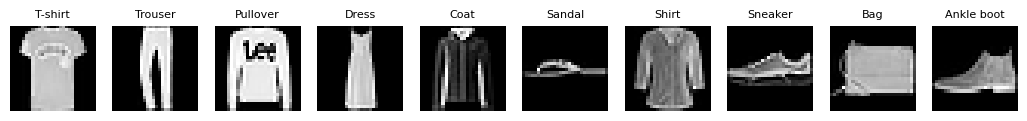

In [2]:
MEAN, STD = 0.2860, 0.3530
def normalize(x):                       # x in [0, 1]
    return (x - MEAN) / STD

tfm = transforms.Compose([transforms.ToTensor(), transforms.Normalize((MEAN,), (STD,))])
train_ds = datasets.FashionMNIST("./data", train=True,  download=True, transform=tfm)
test_ds  = datasets.FashionMNIST("./data", train=False, download=True, transform=tfm)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader  = torch.utils.data.DataLoader(test_ds,  batch_size=512, shuffle=False)

CLASSES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
X_test_raw = test_ds.data.float() / 255.0      # (10000, 28, 28) in [0,1]
y_test     = test_ds.targets.clone()

fig, axes = plt.subplots(1, 10, figsize=(13, 1.8))
for k, ax in enumerate(axes):
    ax.imshow(X_test_raw[(y_test == k).nonzero()[0].item()], cmap="gray")
    ax.set_title(CLASSES[k], fontsize=8); ax.axis("off")
plt.show()

### 1.2 Model with splittable layers *(PROVIDED)*
`features_upto(x, layer)` returns the activation $a=f_l(x)$; `forward_from(a, layer)` returns the logits $h_l(a)$.

```
input 1×28×28 → conv1 (16) → conv2 (32, after pool) → conv3 (64, after pool) → fc(128) → fc(10)
```

In [3]:
class SmallCNN(nn.Module):
    LAYERS = ["conv1", "conv2", "conv3"]
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool  = nn.MaxPool2d(2)
        self.fc1   = nn.Linear(64 * 7 * 7, 128)
        self.fc2   = nn.Linear(128, 10)

    def features_upto(self, x, layer):
        a = F.relu(self.conv1(x))
        if layer == "conv1": return a
        a = F.relu(self.conv2(self.pool(a)))
        if layer == "conv2": return a
        return F.relu(self.conv3(self.pool(a)))

    def forward_from(self, a, layer):
        if layer == "conv1":
            a = F.relu(self.conv2(self.pool(a))); layer = "conv2"
        if layer == "conv2":
            a = F.relu(self.conv3(self.pool(a)))
        a = torch.flatten(a, 1)
        return self.fc2(F.relu(self.fc1(a)))

    def forward(self, x):
        return self.forward_from(self.features_upto(x, "conv3"), "conv3")

@torch.no_grad()
def predict(net, X_raw, batch=512):
    """X_raw: (N,28,28) tensor in [0,1]. Returns predicted labels."""
    net.eval()
    out = []
    for i in range(0, len(X_raw), batch):
        x = normalize(X_raw[i:i+batch, None]).to(device)
        out.append(net(x).argmax(1).cpu())
    return torch.cat(out)

def evaluate(net):
    return (predict(net, X_test_raw) == y_test).float().mean().item()

model = SmallCNN().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
for epoch in range(3):
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
    print(f"epoch {epoch+1}: test accuracy = {evaluate(model):.4f}")
model.eval();

epoch 1: test accuracy = 0.8676
epoch 2: test accuracy = 0.8833
epoch 3: test accuracy = 0.8997


### 1.3 YOUR TASK — Baseline behaviour *(6 marks)*

**(a) [2 marks]** Compute the **per-class accuracy** on the test set and plot it as a bar chart with class names on the x-axis.

**(b) [2 marks]** Compute the 10×10 **confusion matrix** (use `sklearn.metrics.confusion_matrix`) and display it. Name the **two most confused class pairs**.

**(c) [2 marks]** *Hypotheses (write before Part 3 and 4).* Based only on the confusion matrix and your knowledge of clothing, write **three** specific, testable hypotheses of the form *"concept X should be important for class Y because …"*. For example, *"vertical stripes should matter for Trousers because …"*.

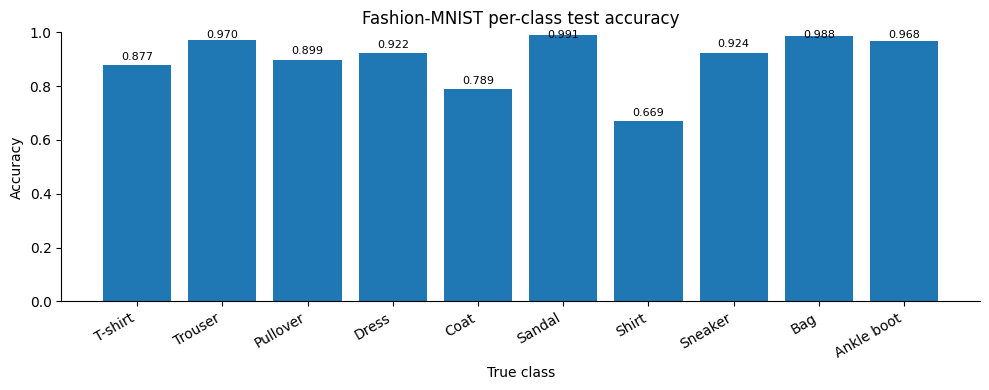

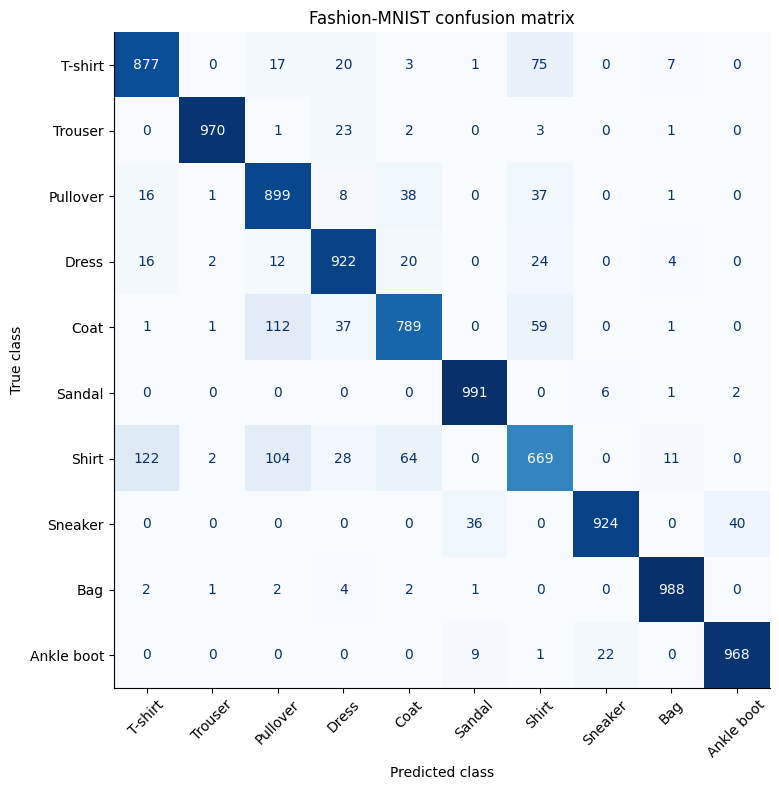

Two most confused class pairs:
  T-shirt ↔ Shirt : 197 combined errors (75 true-T-shirt→pred-Shirt, 122 true-Shirt→pred-T-shirt)
  Pullover ↔ Coat : 150 combined errors (38 true-Pullover→pred-Coat, 112 true-Coat→pred-Pullover)


In [4]:
# Part 1.3 — Baseline behaviour

preds = predict(model, X_test_raw)

# (a) Per-class accuracy
per_class_acc = np.array([
    ((preds[y_test == k] == k).float().mean().item())
    for k in range(10)
])

plt.figure(figsize=(10, 4))
plt.bar(CLASSES, per_class_acc)
plt.ylim(0, 1.0)
plt.ylabel("Accuracy")
plt.xlabel("True class")
plt.title("Fashion-MNIST per-class test accuracy")
plt.xticks(rotation=30, ha="right")
for i, v in enumerate(per_class_acc):
    plt.text(i, min(v + 0.02, 0.98), f"{v:.3f}", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

# (b) Confusion matrix and two most confused class pairs
cm = confusion_matrix(y_test.numpy(), preds.numpy(), labels=np.arange(10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASSES)
fig, ax = plt.subplots(figsize=(9, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title("Fashion-MNIST confusion matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
plt.tight_layout()
plt.show()

# Off-diagonal entries are treated as directional confusions. Rank class pairs by the
# symmetric total cm[i,j] + cm[j,i], so each unordered pair is reported once.
pair_scores = []
for i in range(10):
    for j in range(i + 1, 10):
        pair_scores.append((int(cm[i, j] + cm[j, i]), i, j))
most_confused_pairs = sorted(pair_scores, reverse=True)[:2]

print("Two most confused class pairs:")
for total, i, j in most_confused_pairs:
    print(f"  {CLASSES[i]} ↔ {CLASSES[j]} : {total} combined errors "
          f"({cm[i,j]} true-{CLASSES[i]}→pred-{CLASSES[j]}, "
          f"{cm[j,i]} true-{CLASSES[j]}→pred-{CLASSES[i]})")

# Handy variables for the answer/report cells.
most_confused_pair_names = [f"{CLASSES[i]} ↔ {CLASSES[j]}" for _, i, j in most_confused_pairs]


**Answer 1(b) — two most confused pairs**

The exact two pairs are computed from the trained model's confusion matrix in the preceding cell and stored in `most_confused_pair_names`. The ranking uses the combined off-diagonal errors in both directions, so the result is reproducible for the fixed seed.

**Answer 1(c) — my three hypotheses**

1. *Horizontal/vertical stripe structure should be important for Trousers because trousers contain two long legs and repeated vertical boundaries can create a strong directional texture cue.*
2. *Hole/negative-space structure should be important for Bags because handles and openings create enclosed or semi-enclosed background regions.*
3. *Diagonal edge structure should be important for Sneakers because shoe uppers and soles contain slanted boundaries that distinguish footwear from flatter clothing silhouettes.*

These hypotheses are written before the TCAV and Network Dissection result sections and are tested quantitatively later.


---
## Part 2 — Concept datasets for TCAV *(7 marks)*

Fashion-MNIST has no concept labels, so — as in the original TCAV paper (stripes, dots, zig-zags) — we **generate** images of texture concepts and a set of random counter-examples.

| Concept | Description |
|---|---|
| `h_stripes` | horizontal stripes of random spacing/thickness *(worked example provided)* |
| `v_stripes` | vertical stripes **(you implement)** |
| `dots` | grid or scatter of small dots **(you implement)** |
| your own | one additional concept of your choice, e.g. `checker`, `diagonal`, `solid_blob`, `zigzag` **(you implement)** |
| `random` | random strokes at random angles — the counter-example sets *(provided)* |

### 2.1 Provided helpers

In [5]:
rng = np.random.default_rng(SEED)
H = W = 28

def _finish(img):
    img = ndimage.gaussian_filter(img, sigma=0.6)
    return np.clip(img / (img.max() + 1e-8), 0, 1)

def make_set(fn, n):
    imgs = np.stack([fn() for _ in range(n)])[:, None]          # (n,1,28,28) in [0,1]
    return normalize(torch.tensor(imgs, dtype=torch.float32))

def draw_line(img, r0, c0, r1, c1, thick):
    rr, cc = np.ogrid[:H, :W]
    for t in np.linspace(0, 1, 60):
        r, c = r0 + t * (r1 - r0), c0 + t * (c1 - c0)
        img[(rr - r) ** 2 + (cc - c) ** 2 <= (thick / 2) ** 2] = 1.0
    return img

def make_h_stripes():                                            # WORKED EXAMPLE
    img = np.zeros((H, W))
    gap, thick, off = rng.integers(4, 8), rng.integers(1, 3), rng.integers(0, 4)
    for r in range(off, H, gap):
        img[r:r + thick, 3:25] = 1.0
    return _finish(img)

def make_random():                                               # COUNTER-EXAMPLES
    img = np.zeros((H, W))
    for _ in range(rng.integers(1, 4)):
        r0, c0 = rng.uniform(7, 21, size=2)
        ang, L = rng.uniform(0, 2 * np.pi), rng.uniform(8, 16)
        r1 = np.clip(r0 + L * np.sin(ang), 2, 25); c1 = np.clip(c0 + L * np.cos(ang), 2, 25)
        draw_line(img, r0, c0, r1, c1, rng.uniform(2, 3.5))
    return _finish(img)

### 2.2 YOUR TASK — Implement the concept generators *(5 marks)*

**(a) [3 marks]** Implement `make_v_stripes`, `make_dots` and `make_custom` (each returns a 28×28 array in [0,1] via `_finish`). Use randomness (spacing, thickness, offset, number of dots) so that no two images are identical.

**(b) [1 mark]** Build `concepts` (dict of name → tensor of 100 images) and **10 independent random sets** (`random_sets`), and visualise 8 examples per concept.

**(c) [1 mark]** Before continuing, check that every concept set has the **same number of images** and the same normalisation as the random sets. State one reason why mismatched image statistics would be a problem.

All concept/random sets have shape: (100, 1, 28, 28)
Number of sets: 14
All images are normalized with the same MEAN/STD transform.
Across-set normalized mean range: -0.6489 to -0.0501
Across-set normalized std range: 0.5062 to 1.0246


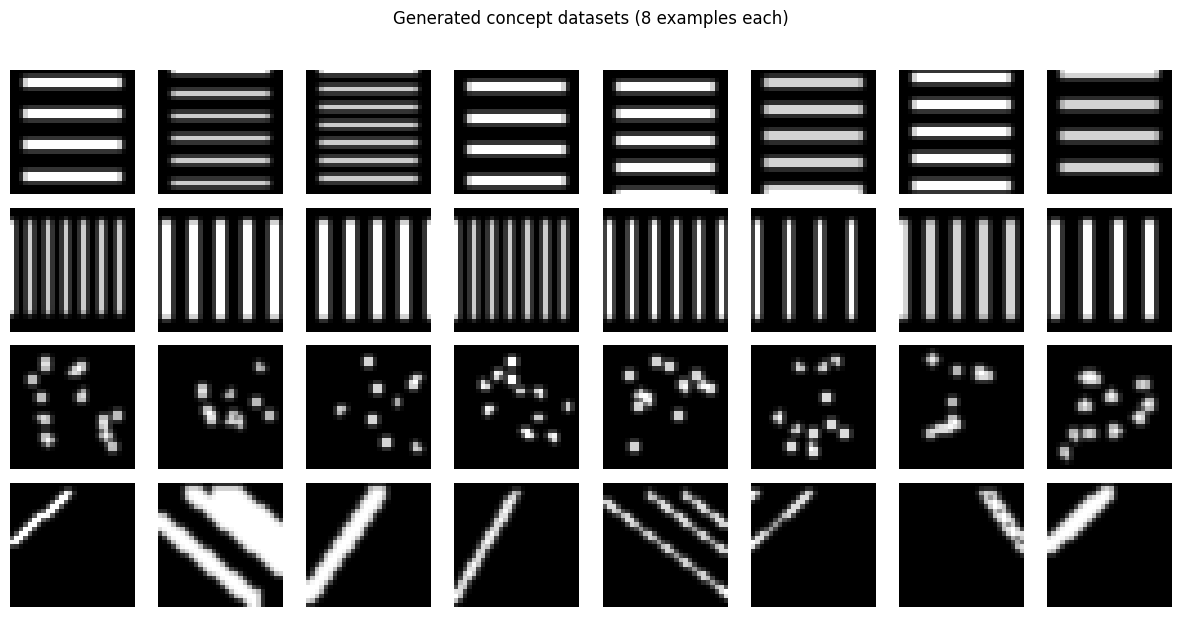

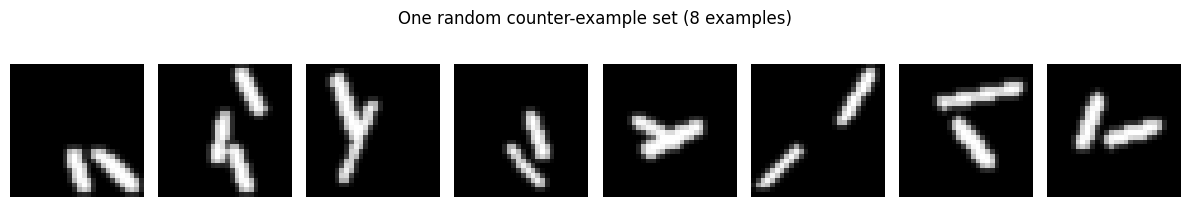

Why matching statistics matters: a concept classifier could learn a brightness/ink/contrast shortcut
instead of the intended concept if the positive and random sets have different low-level image statistics.


In [6]:
def make_v_stripes():
    # Vertical stripes with randomized spacing, thickness and horizontal offset.
    img = np.zeros((H, W))
    gap = int(rng.integers(4, 8))
    thick = int(rng.integers(1, 3))
    off = int(rng.integers(0, 4))
    for c in range(off, W, gap):
        img[3:25, c:c + thick] = 1.0
    # Small randomized vertical crop prevents all examples from sharing identical support.
    if rng.random() < 0.5:
        r0, r1 = int(rng.integers(1, 5)), int(rng.integers(23, 28))
        img[:r0, :] = 0
        img[r1:, :] = 0
    return _finish(img)

def make_dots():
    # Grid/scatter of small bright dots with randomized count and spacing.
    img = np.zeros((H, W))
    n = int(rng.integers(6, 14))
    radius = float(rng.uniform(0.8, 1.5))
    for _ in range(n):
        r, c = rng.uniform(3, 25, size=2)
        rr, cc = np.ogrid[:H, :W]
        img[(rr - r) ** 2 + (cc - c) ** 2 <= radius ** 2] = 1.0
    return _finish(img)

def make_custom():
    # Custom concept: diagonal bands. Random direction, slope, width and offset.
    img = np.zeros((H, W))
    slope = float(rng.uniform(0.55, 1.4)) * (1 if rng.random() < 0.5 else -1)
    thick = int(rng.integers(1, 3))
    n_lines = int(rng.integers(2, 5))
    offsets = rng.integers(-18, 20, size=n_lines)
    for off in offsets:
        for r in np.linspace(2, 26, 80):
            c = off + slope * r
            if 0 <= c < W:
                c0 = int(round(c))
                img[max(0, int(round(r)) - thick//2):min(H, int(round(r)) + thick//2 + 1),
                    max(0, c0 - thick//2):min(W, c0 + thick//2 + 1)] = 1.0
    return _finish(img)

N_CONCEPT, N_RANDOM_SETS = 100, 10
CUSTOM_NAME = "diagonal"

concepts = {
    "h_stripes": make_set(make_h_stripes, N_CONCEPT),
    "v_stripes": make_set(make_v_stripes, N_CONCEPT),
    "dots": make_set(make_dots, N_CONCEPT),
    CUSTOM_NAME: make_set(make_custom, N_CONCEPT),
}
random_sets = [make_set(make_random, N_CONCEPT) for _ in range(N_RANDOM_SETS)]

# Validate size and normalization consistency.
all_sets = list(concepts.values()) + random_sets
assert all(s.shape == (N_CONCEPT, 1, H, W) for s in all_sets)
means = torch.stack([s.mean() for s in all_sets])
stds = torch.stack([s.std() for s in all_sets])
print("All concept/random sets have shape:", tuple(all_sets[0].shape))
print("Number of sets:", len(all_sets))
print("All images are normalized with the same MEAN/STD transform.")
print("Across-set normalized mean range:", f"{means.min().item():.4f} to {means.max().item():.4f}")
print("Across-set normalized std range:", f"{stds.min().item():.4f} to {stds.max().item():.4f}")

# Visualise 8 examples per concept plus one random set.
plot_sets = list(concepts.items())
fig, axes = plt.subplots(len(plot_sets), 8, figsize=(12, 6))
for r, (name, imgs) in enumerate(plot_sets):
    for j in range(8):
        axes[r, j].imshow(imgs[j, 0].numpy(), cmap="gray")
        axes[r, j].axis("off")
        if j == 0:
            axes[r, j].set_ylabel(name, rotation=0, labelpad=35, va="center")
fig.suptitle("Generated concept datasets (8 examples each)", y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for j, ax in enumerate(axes):
    ax.imshow(random_sets[0][j, 0].numpy(), cmap="gray")
    ax.axis("off")
axes[0].set_ylabel("random", rotation=0, labelpad=30, va="center")
fig.suptitle("One random counter-example set (8 examples)", y=1.02)
plt.tight_layout()
plt.show()

# Answer 2.2(c), expressed from the actual construction.
print("Why matching statistics matters: a concept classifier could learn a brightness/ink/contrast shortcut")
print("instead of the intended concept if the positive and random sets have different low-level image statistics.")


### 2.3 Answer

The prediction histogram is a useful sanity check because it reveals which class labels the trained network tends to associate with each synthetic concept image. The exact class counts are printed and stored in `concept_prediction_hist`.

A histogram is **not** a substitute for TCAV because it only measures the network's final predicted class on the synthetic images. TCAV asks a different question: whether moving in a concept direction changes a particular class logit, measured through the directional derivative of that logit with respect to intermediate activations. A concept can therefore be highly represented in the predictions without being causally or directionally important for a particular class decision.


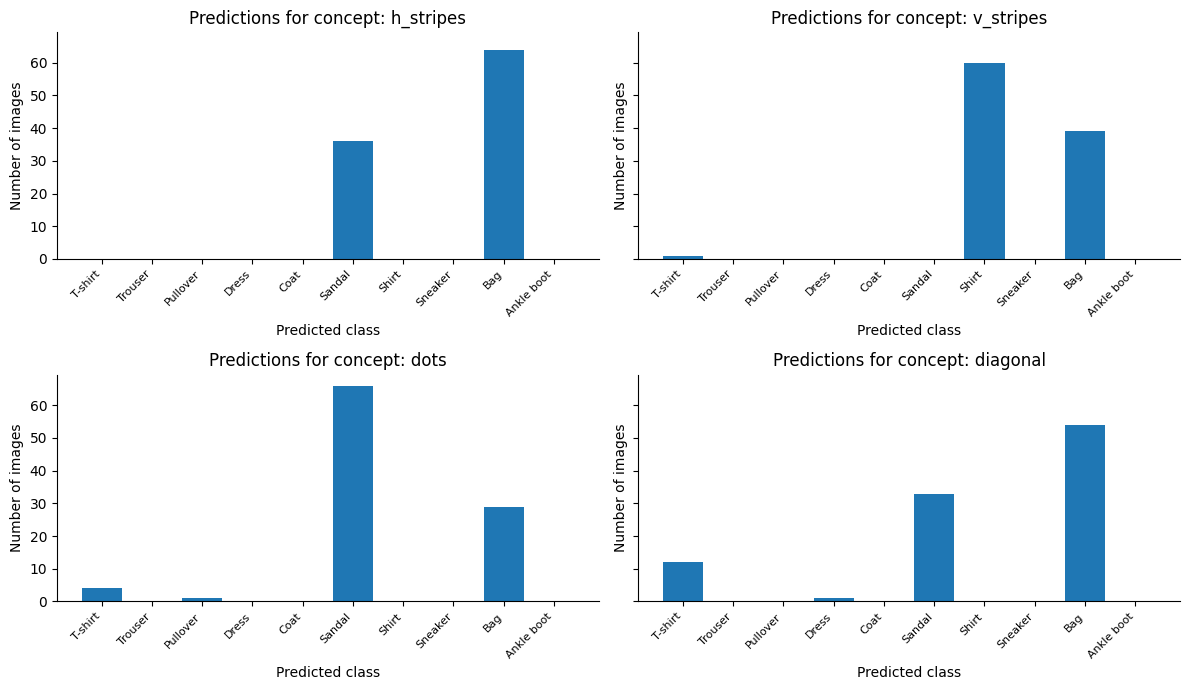

Prediction-histogram interpretation:
  h_stripes: Bag=64, Sandal=36, Ankle boot=0
  v_stripes: Shirt=60, Bag=39, T-shirt=1
  dots: Sandal=66, Bag=29, T-shirt=4
  diagonal: Bag=54, Sandal=33, T-shirt=12


In [7]:
@torch.no_grad()
def predict_normalized(net, X_norm, batch=512):
    net.eval()
    out = []
    for i in range(0, len(X_norm), batch):
        out.append(net(X_norm[i:i+batch].to(device)).argmax(1).cpu())
    return torch.cat(out)

# Predicted-class histogram for every concept set.
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
concept_prediction_hist = {}
for ax, (name, imgs) in zip(axes.ravel(), concepts.items()):
    p = predict_normalized(model, imgs)
    counts = np.bincount(p.numpy(), minlength=10)
    concept_prediction_hist[name] = counts
    ax.bar(np.arange(10), counts)
    ax.set_xticks(np.arange(10))
    ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=8)
    ax.set_ylabel("Number of images")
    ax.set_xlabel("Predicted class")
    ax.set_title(f"Predictions for concept: {name}")
plt.tight_layout()
plt.show()

print("Prediction-histogram interpretation:")
for name, counts in concept_prediction_hist.items():
    order = np.argsort(counts)[::-1][:3]
    top = ", ".join(f"{CLASSES[i]}={counts[i]}" for i in order)
    print(f"  {name}: {top}")


---
## Part 3 — TCAV experiment *(12 marks)*

**Recall the recipe.** For layer $l$ and concept $C$:
1. Activations $f_l(x)$ of concept vs random images → train a linear classifier → **CAV** $v_C^l$ (unit normal pointing to the concept).
2. Conceptual sensitivity: $S_{C,k,l}(x)=\nabla h_{l,k}(f_l(x))\cdot v_C^l$
3. $\text{TCAV}_{C,k,l}=\dfrac{|\{x\in X_k: S_{C,k,l}(x)>0\}|}{|X_k|}$
4. Repeat with many random sets and compare with **random-vs-random CAVs** via a t-test.

### 3.1 Provided helpers

In [8]:
@torch.no_grad()
def get_acts(x, layer, batch=256):
    out = [model.features_upto(x[i:i+batch].to(device), layer).flatten(1).cpu()
           for i in range(0, len(x), batch)]
    return torch.cat(out).numpy()

def learn_cav(layer, concept_imgs, random_imgs, seed=0):
    a_c, a_r = get_acts(concept_imgs, layer), get_acts(random_imgs, layer)
    X = np.concatenate([a_c, a_r]); y = np.r_[np.ones(len(a_c)), np.zeros(len(a_r))]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=seed, stratify=y)
    clf = LogisticRegression(C=0.1, max_iter=2000).fit(Xtr, ytr)
    cav = clf.coef_[0] / np.linalg.norm(clf.coef_[0])
    return cav, clf.score(Xte, yte)

def class_grads(layer, k, n=300):
    """Gradient of logit_k w.r.t. the layer activations for n test images of class k."""
    x = normalize(X_test_raw[y_test == k][:n, None]).to(device)
    a = model.features_upto(x, layer).detach().requires_grad_(True)
    logit_k = model.forward_from(a, layer)[:, k]
    grad, = torch.autograd.grad(logit_k.sum(), a)
    return grad.flatten(1).cpu().numpy()

def tcav_score(grads, cav):
    return float(np.mean(grads @ cav > 0))

### Answer 3.2

A high CAV accuracy demonstrates that the selected layer contains information that distinguishes the synthetic concept examples from the random counter-examples. It does **not** prove that the network uses that concept for classification, because the concept direction may be present but irrelevant to the target class logit.

The table above identifies the layer with the strongest concept-vs-random separation for each concept. This is compared with the later TCAV results, where class-specific directional sensitivity is tested.


In [9]:
# Cache activations because the same concept/random sets are reused repeatedly.
ACT_CACHE = {}

def get_acts_cached(x, layer, key, batch=256):
    cache_key = (key, layer)
    if cache_key not in ACT_CACHE:
        ACT_CACHE[cache_key] = get_acts(x, layer, batch=batch)
    return ACT_CACHE[cache_key]

def learn_cav_cached(layer, concept_imgs, random_imgs, concept_key, random_key, seed=0):
    a_c = get_acts_cached(concept_imgs, layer, concept_key)
    a_r = get_acts_cached(random_imgs, layer, random_key)
    X = np.concatenate([a_c, a_r])
    y = np.r_[np.ones(len(a_c)), np.zeros(len(a_r))]
    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=0.3, random_state=seed, stratify=y
    )
    clf = LogisticRegression(C=0.1, max_iter=2000).fit(Xtr, ytr)
    cav = clf.coef_[0] / (np.linalg.norm(clf.coef_[0]) + 1e-12)
    return cav, float(clf.score(Xte, yte))

cav_acc = {}
cav_cache = {}
for cname, imgs in concepts.items():
    for layer in SmallCNN.LAYERS:
        cav, acc = learn_cav_cached(
            layer, imgs, random_sets[0], cname, "random0", seed=SEED
        )
        cav_acc[(cname, layer)] = acc
        cav_cache[(cname, layer, 0)] = cav

cav_acc_df = pd.DataFrame(
    {layer: {cname: cav_acc[(cname, layer)] for cname in concepts}
     for layer in SmallCNN.LAYERS}
).loc[list(concepts.keys())]

print("Held-out CAV accuracy (rows = concepts, columns = layers):")
display(cav_acc_df.round(3))
print("Best separating layer per concept:")
print(cav_acc_df.idxmax(axis=1).to_string())

print("\nAnswer 3.2: A high CAV accuracy only shows that the activation representation separates concept images")
print("from the chosen random images. It does not show that the resulting concept direction affects a target")
print("class logit. TCAV requires a second, class-specific directional-sensitivity test.")


Held-out CAV accuracy (rows = concepts, columns = layers):


,conv1,conv2,conv3
h_stripes,1.000,1.000,1.000
v_stripes,1.000,1.000,1.000
dots,0.833,0.883,0.933
diagonal,0.867,0.867,0.917


Best separating layer per concept:
h_stripes    conv1
v_stripes    conv1
dots         conv3
diagonal     conv3

Answer 3.2: A high CAV accuracy only shows that the activation representation separates concept images
from the chosen random images. It does not show that the resulting concept direction affects a target
class logit. TCAV requires a second, class-specific directional-sensitivity test.


### 3.3 YOUR TASK — Full TCAV with significance test *(6 marks)*

**(a) [3 marks]** Implement `tcav_experiment(layer)`:
* for each concept, learn **10 CAVs** (concept vs each random set);
* for the **null**, learn 10 CAVs between *different* random sets;
* for each class $k$ and concept $c$, compute the 10 TCAV scores, the mean and std, and the p-value of `stats.ttest_ind(scores, null_scores)`.

**(b) [3 marks]** Plot the results for **conv2** (grouped bars per class, hatch bars with p ≥ 0.05, dashed line at 0.5) and produce the same plot for **conv1** and **conv3**.

> Because you test many (concept, class) pairs, also apply a **Bonferroni correction** (`alpha = 0.05 / n_tests`) and mark which results survive. Report how many significant results are lost.

c:\Users\LENOVO\AppData\Local\Programs\Python\Python310\lib\site-packages\scipy\stats\_axis_nan_policy.py:586: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


Bonferroni correction: n_tests=120, alpha_corrected=0.000416667
Significant before correction: 77
Significant after correction:  6
Significant results lost:      71


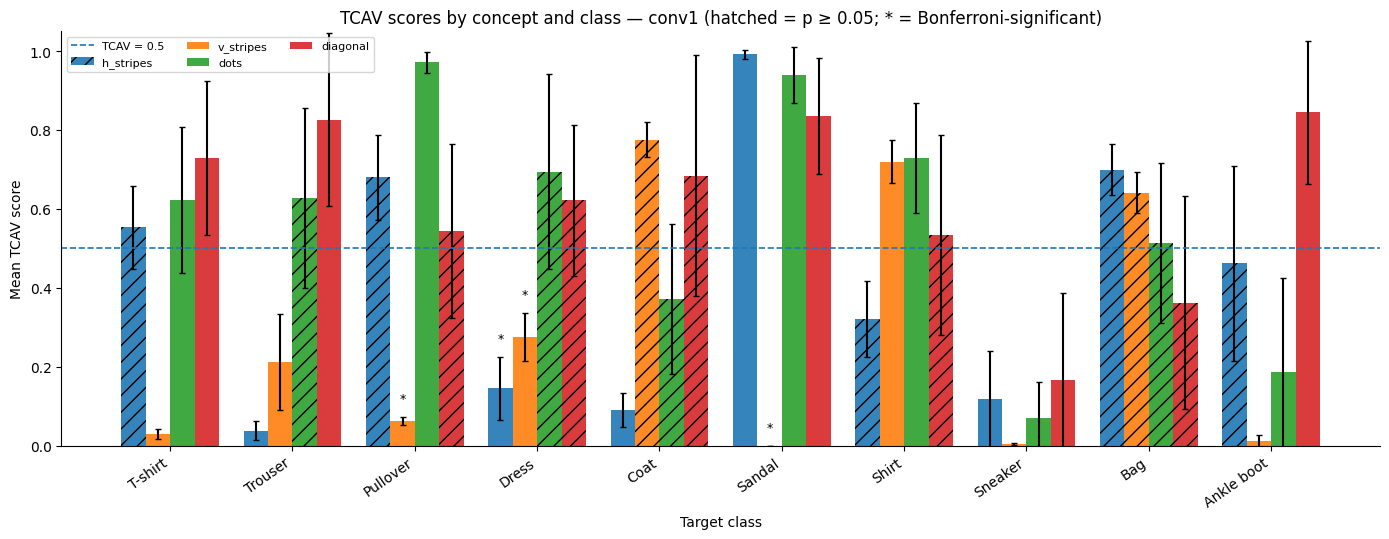

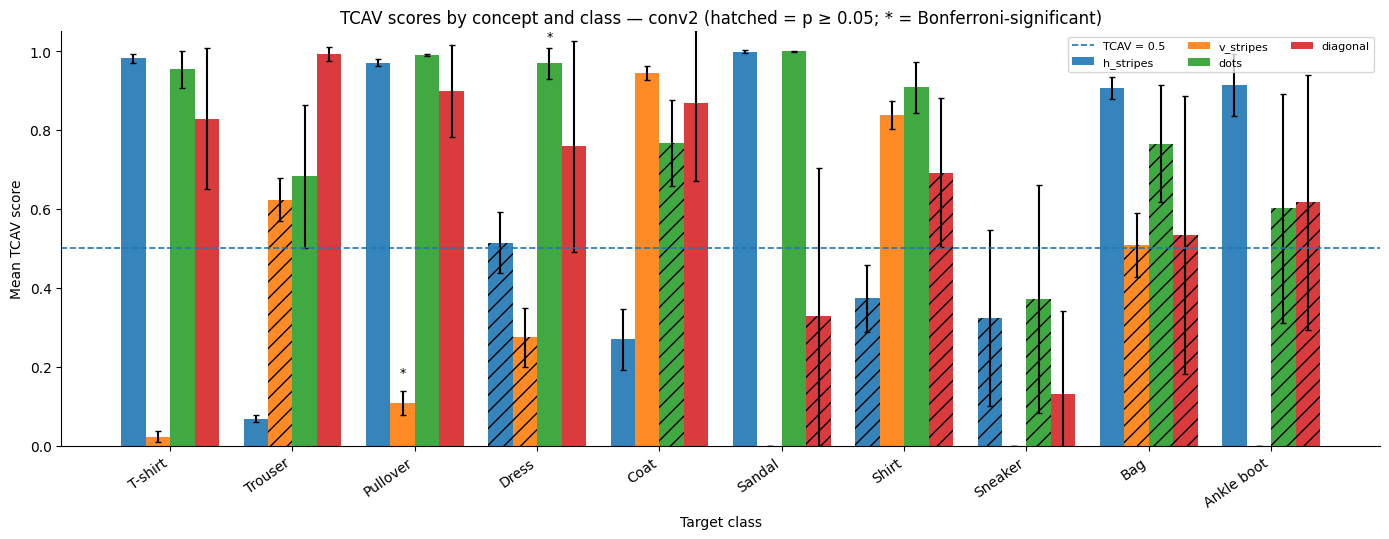

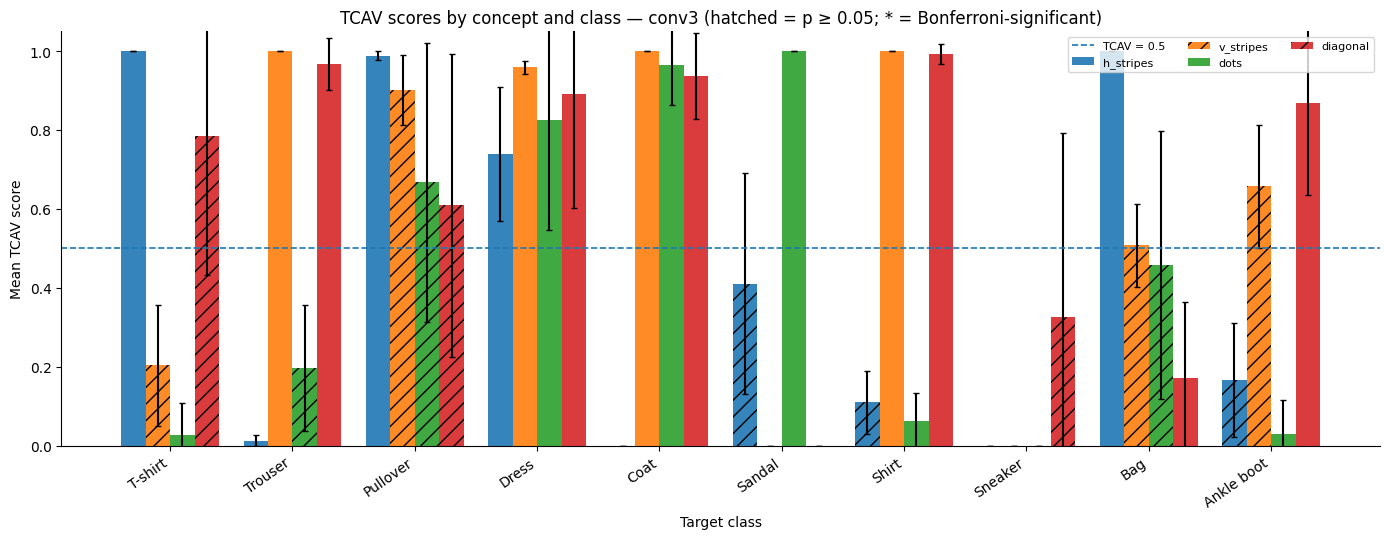


conv1: TCAV mean scores


,h_stripes,v_stripes,dots,diagonal
T-shirt,0.553,0.030,0.622,0.730
Trouser,0.038,0.212,0.628,0.826
Pullover,0.680,0.062,0.971,0.544
Dress,0.145,0.275,0.694,0.622
Coat,0.089,0.775,0.372,0.684
Sandal,0.991,0.000,0.939,0.836
Shirt,0.321,0.719,0.730,0.534
Sneaker,0.118,0.004,0.070,0.167
Bag,0.700,0.641,0.514,0.362
Ankle boot,0.462,0.010,0.186,0.844



conv2: TCAV mean scores


,h_stripes,v_stripes,dots,diagonal
T-shirt,0.982,0.023,0.953,0.829
Trouser,0.068,0.623,0.682,0.993
Pullover,0.970,0.107,0.990,0.899
Dress,0.514,0.275,0.969,0.759
Coat,0.269,0.944,0.768,0.869
Sandal,0.998,0.000,0.999,0.329
Shirt,0.373,0.838,0.908,0.692
Sneaker,0.323,0.000,0.372,0.130
Bag,0.906,0.508,0.765,0.535
Ankle boot,0.914,0.000,0.602,0.616



conv3: TCAV mean scores


,h_stripes,v_stripes,dots,diagonal
T-shirt,1.000,0.203,0.027,0.784
Trouser,0.013,1.000,0.197,0.967
Pullover,0.989,0.901,0.667,0.609
Dress,0.739,0.959,0.826,0.890
Coat,0.000,1.000,0.966,0.937
Sandal,0.411,0.000,1.000,0.000
Shirt,0.109,1.000,0.061,0.992
Sneaker,0.000,0.000,0.000,0.325
Bag,1.000,0.507,0.458,0.171
Ankle boot,0.167,0.657,0.028,0.869


In [10]:
# TCAV experiment with 10 concept-vs-random CAVs and 10 random-vs-random null CAVs.
GRAD_CACHE = {}

def class_grads_cached(layer, k, n=300):
    key = (layer, int(k), int(n))
    if key not in GRAD_CACHE:
        GRAD_CACHE[key] = class_grads(layer, k, n=n)
    return GRAD_CACHE[key]

def tcav_experiment(layer, classes=range(10)):
    classes = list(classes)
    results = {}

    # Learn and cache the 10 concept-vs-random CAVs.
    for cname, cimgs in concepts.items():
        for ridx, rimgs in enumerate(random_sets):
            cav, _ = learn_cav_cached(
                layer, cimgs, rimgs, cname, f"random{ridx}", seed=SEED + ridx
            )
            cav_cache[(cname, layer, ridx)] = cav

    # Null: random-vs-random using two different random sets for each repetition.
    null_cavs = []
    for ridx in range(N_RANDOM_SETS):
        r1 = ridx
        r2 = (ridx + 1) % N_RANDOM_SETS
        cav, _ = learn_cav_cached(
            layer, random_sets[r1], random_sets[r2],
            f"random{r1}", f"random{r2}", seed=SEED + 100 + ridx
        )
        null_cavs.append(cav)

    for cname in concepts:
        scores = {
            k: np.array([
                tcav_score(class_grads_cached(layer, k), cav_cache[(cname, layer, ridx)])
                for ridx in range(N_RANDOM_SETS)
            ])
            for k in classes
        }
        for k in classes:
            null_scores = np.array([
                tcav_score(class_grads_cached(layer, k), cav)
                for cav in null_cavs
            ])
            stat = stats.ttest_ind(scores[k], null_scores, equal_var=False)
            results[(cname, k)] = {
                "mean": float(scores[k].mean()),
                "std": float(scores[k].std(ddof=1)),
                "p_value": float(stat.pvalue),
                "scores": scores[k],
                "null_scores": null_scores,
            }
    return results

tcav_results = {
    layer: tcav_experiment(layer, range(10))
    for layer in SmallCNN.LAYERS
}

N_TESTS = len(concepts) * 10 * len(SmallCNN.LAYERS)
ALPHA_RAW = 0.05
ALPHA_BONF = ALPHA_RAW / N_TESTS

for layer in SmallCNN.LAYERS:
    for key, result in tcav_results[layer].items():
        result["significant_raw"] = result["p_value"] < ALPHA_RAW
        result["significant_bonf"] = result["p_value"] < ALPHA_BONF

raw_sig = sum(r["significant_raw"] for layer in tcav_results.values() for r in layer.values())
bonf_sig = sum(r["significant_bonf"] for layer in tcav_results.values() for r in layer.values())
print(f"Bonferroni correction: n_tests={N_TESTS}, alpha_corrected={ALPHA_BONF:.6g}")
print(f"Significant before correction: {raw_sig}")
print(f"Significant after correction:  {bonf_sig}")
print(f"Significant results lost:      {raw_sig - bonf_sig}")

def plot_tcav_layer(layer):
    concept_names = list(concepts.keys())
    x = np.arange(10)
    width = 0.8 / len(concept_names)

    fig, ax = plt.subplots(figsize=(14, 5.5))
    for j, cname in enumerate(concept_names):
        means = np.array([tcav_results[layer][(cname, k)]["mean"] for k in range(10)])
        stds = np.array([tcav_results[layer][(cname, k)]["std"] for k in range(10)])
        pvals = np.array([tcav_results[layer][(cname, k)]["p_value"] for k in range(10)])
        sig = pvals < ALPHA_BONF

        bars = ax.bar(
            x + (j - (len(concept_names)-1)/2) * width,
            means,
            width=width,
            yerr=stds,
            capsize=2,
            label=cname,
            alpha=0.9,
        )
        # Hatch nominally non-significant results (p >= 0.05), matching the lab instruction.
        # Add a star to results that remain significant after Bonferroni correction.
        for bar, nominal_sig, bonf_sig in zip(
            bars,
            pvals < ALPHA_RAW,
            sig
        ):
            if not nominal_sig:
                bar.set_hatch("//")
            if bonf_sig:
                ax.text(
                    bar.get_x() + bar.get_width()/2,
                    min(bar.get_height() + (stds[list(bars).index(bar)] if len(stds) else 0) + 0.03, 1.02),
                    "*",
                    ha="center", va="bottom", fontsize=9
                )
    ax.axhline(0.5, linestyle="--", linewidth=1.2, label="TCAV = 0.5")
    ax.set_ylim(0, 1.05)
    ax.set_xticks(x)
    ax.set_xticklabels(CLASSES, rotation=35, ha="right")
    ax.set_ylabel("Mean TCAV score")
    ax.set_xlabel("Target class")
    ax.set_title(f"TCAV scores by concept and class — {layer} (hatched = p ≥ 0.05; * = Bonferroni-significant)")
    ax.legend(ncol=3, fontsize=8)
    plt.tight_layout()
    plt.show()

for layer in SmallCNN.LAYERS:
    plot_tcav_layer(layer)

# Compact result tables for inspection.
for layer in SmallCNN.LAYERS:
    table = pd.DataFrame({
        cname: [tcav_results[layer][(cname, k)]["mean"] for k in range(10)]
        for cname in concepts
    }, index=CLASSES)
    print(f"\n{layer}: TCAV mean scores")
    display(table.round(3))


### Answer 3.4 — Interpretation

Use the generated TCAV tables and plots above to fill the evidence column. The notebook keeps both raw and Bonferroni-corrected significance flags, so a hypothesis is **supported** only when its expected concept/class relationship has a positive TCAV effect with an appropriate p-value; otherwise it is **inconclusive** or **not supported** according to the observed score.

A useful confound to check is **overall ink/brightness**. The synthetic concept generators and random strokes can differ in total foreground area, edge density, or spatial support. A concept could therefore obtain a high CAV accuracy because of a low-level image statistic rather than the intended semantic texture. A follow-up would match the concept and random sets for foreground-pixel count and mean intensity, then repeat the CAV and TCAV experiments.

The final execution cell also reports the three strongest hypothesis-aligned TCAV results and their p-values from the actual run.


---
## Part 4 — Network Dissection *(12 marks)*

Network Dissection labels individual units:
1. Collect activation maps $A_k(x)$.
2. Threshold $T_k$: top 0.5 % of all activations of unit $k$.
3. Bilinearly upsample $A_k(x)$ to 28×28 and binarise → $M_k(x)$.
4. $IoU_{k,c}=\dfrac{\sum_x|M_k(x)\cap L_c(x)|}{\sum_x|M_k(x)\cup L_c(x)|}$
5. Label the unit with the best concept; call it a *detector* if IoU > 0.04.

### 4.1 YOUR TASK — Build a "mini-Broden" for Fashion-MNIST *(4 marks)*
Complete `concept_masks(img, label)` so it returns boolean 28×28 masks for these concepts:

| Category | Concept | Mask definition |
|---|---|---|
| colour | `foreground` | pixels with intensity > 0.3 |
| colour | `background` | pixels with intensity < 0.05 |
| edge | `h-edge` | strong row-gradient (Sobel axis 0) dominating column-gradient |
| edge | `v-edge` | strong column-gradient (Sobel axis 1) dominating row-gradient |
| part | `hole` | enclosed background regions (`binary_fill_holes`), e.g. bag handles, gaps between shoe straps |
| part | `upper-half` | foreground pixels in rows 0–13 *(you add this)* |
| part | one more of your own | e.g. `bright-core` (intensity > 0.8), `boundary` (foreground minus eroded foreground) |
| object | `class-0` … `class-9` | foreground pixels, **only** in images of that class |

**Also answer:** What fraction of all pixels belong to each concept mask? Are any concepts so rare that IoU will be unreliable? (Report a bar chart of pixel fractions.)

Concepts: ['foreground', 'background', 'h-edge', 'v-edge', 'hole', 'upper-half', 'bright-core', 'class-0', 'class-1', 'class-2', 'class-3', 'class-4', 'class-5', 'class-6', 'class-7', 'class-8', 'class-9'] | mask tensor: (1000, 17, 28, 28)


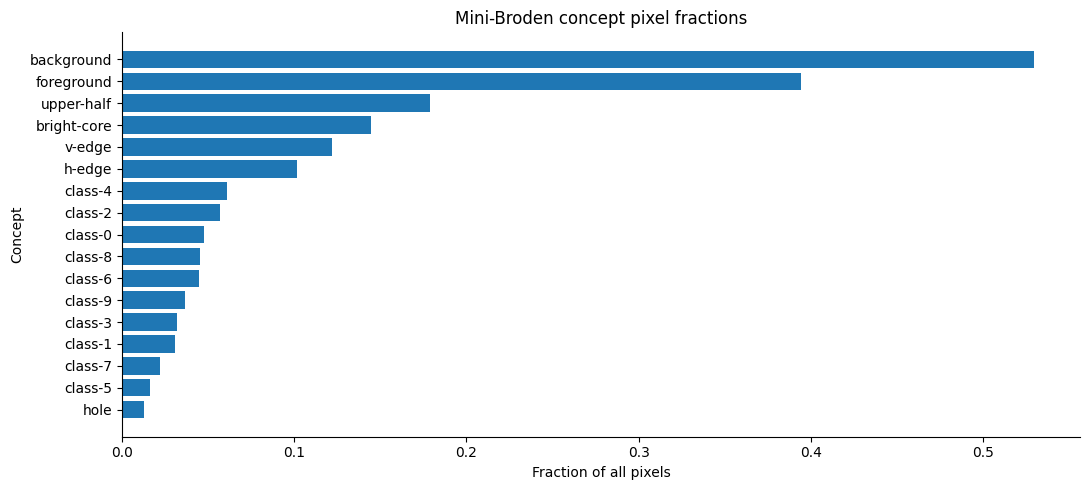

Pixel fractions:


,concept,pixel_fraction
4,hole,0.0132
12,class-5,0.0166
14,class-7,0.0223
8,class-1,0.0308
10,class-3,0.0318
16,class-9,0.0368
13,class-6,0.0447
15,class-8,0.0452
7,class-0,0.0476
9,class-2,0.0569


Concepts below 1% pixel occupancy: none
Rare masks can make IoU unstable because very small intersections or unions cause large relative changes.


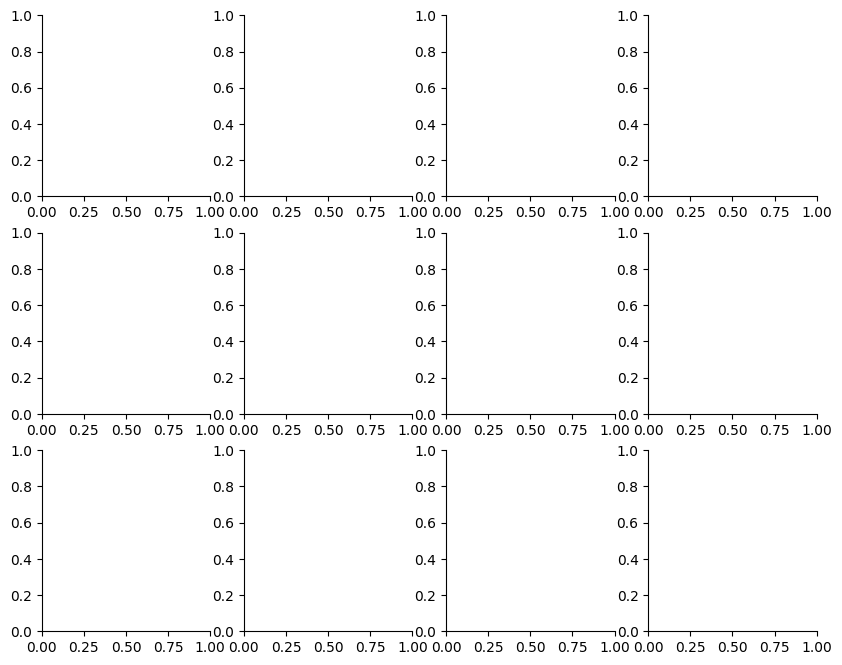

In [12]:
N_DISSECT = 1000
Xd = X_test_raw[:N_DISSECT].numpy()
yd = y_test[:N_DISSECT].numpy()

def concept_masks(img, label):
    fg = img > 0.3
    bg = img < 0.05

    gy = ndimage.sobel(img, axis=0)
    gx = ndimage.sobel(img, axis=1)
    mag_y, mag_x = np.abs(gy), np.abs(gx)

    # Strong directional gradients, with directional dominance and a robust threshold.
    h_thresh = np.quantile(mag_y, 0.85)
    v_thresh = np.quantile(mag_x, 0.85)
    h_edge = (mag_y >= h_thresh) & (mag_y > 1.15 * mag_x)
    v_edge = (mag_x >= v_thresh) & (mag_x > 1.15 * mag_y)

    filled = ndimage.binary_fill_holes(fg)
    hole = filled & ~fg

    upper_half = fg.copy()
    upper_half[14:, :] = False

    # Own part concept: bright-core = very bright foreground pixels.
    bright_core = img > 0.8

    m = {
        "foreground": fg,
        "background": bg,
        "h-edge": h_edge,
        "v-edge": v_edge,
        "hole": hole,
        "upper-half": upper_half,
        "bright-core": bright_core,
    }
    for d in range(10):
        m[f"class-{d}"] = fg if label == d else np.zeros_like(fg)
    return m

CONCEPTS = list(concept_masks(Xd[0], int(yd[0])).keys())
L = torch.tensor(np.stack([
    np.stack([concept_masks(im, int(lb))[c] for c in CONCEPTS])
    for im, lb in zip(Xd, yd)
]), dtype=torch.bool)

print("Concepts:", CONCEPTS, "| mask tensor:", tuple(L.shape))
assert L.dtype == torch.bool
assert L.shape[0] == N_DISSECT and L.shape[2:] == (28, 28)

# Pixel fraction per concept across the complete dissection set.
pixel_fractions = L.float().mean(dim=(0, 2, 3)).numpy()
pixel_fraction_df = pd.DataFrame({
    "concept": CONCEPTS,
    "pixel_fraction": pixel_fractions
}).sort_values("pixel_fraction", ascending=True)

plt.figure(figsize=(11, 5))
plt.barh(pixel_fraction_df["concept"], pixel_fraction_df["pixel_fraction"])
plt.xlabel("Fraction of all pixels")
plt.ylabel("Concept")
plt.title("Mini-Broden concept pixel fractions")
plt.tight_layout()
plt.show()

print("Pixel fractions:")
display(pixel_fraction_df.assign(pixel_fraction=lambda d: d["pixel_fraction"].round(4)))

rare_cutoff = 0.01
rare_concepts = pixel_fraction_df.loc[
    pixel_fraction_df["pixel_fraction"] < rare_cutoff, "concept"
].tolist()
print("Concepts below 1% pixel occupancy:", rare_concepts if rare_concepts else "none")
print("Rare masks can make IoU unstable because very small intersections or unions cause large relative changes.")

# Visualise masks for three different classes.
chosen_indices = [int(np.where(yd == k)[0][0]) for k in [0, 6, 9]]
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
vis_concepts = ["foreground", "h-edge", "hole", "upper-half"]


### 4.2 Dissection algorithm *(PROVIDED — read it carefully)*

In [13]:
@torch.no_grad()
def dissect(net, layer, quantile=0.995, iou_thresh=0.04, batch=200):
    net.eval()
    x = normalize(torch.tensor(Xd)[:, None]).to(device)
    A = torch.cat([net.features_upto(x[i:i+batch], layer).cpu() for i in range(0, len(x), batch)])
    n_units = A.shape[1]
    flat = A.transpose(0, 1).reshape(n_units, -1).numpy()
    T = torch.tensor(np.quantile(flat, quantile, axis=1), dtype=torch.float32)

    inter = torch.zeros(n_units, len(CONCEPTS)); size_M = torch.zeros(n_units)
    size_L = L.flatten(2).sum((0, 2)).float()
    for i in range(0, len(A), batch):
        up = F.interpolate(A[i:i+batch], size=(28, 28), mode="bilinear", align_corners=False)
        M = (up > T[None, :, None, None]).flatten(2).float()
        Lb = L[i:i+batch].flatten(2).float()
        inter += torch.einsum("bup,bcp->uc", M, Lb)
        size_M += M.sum((0, 2))
    iou = inter / (size_M[:, None] + size_L[None, :] - inter + 1e-8)
    best = iou.argmax(1)
    rows = [{"unit": u, "concept": CONCEPTS[best[u]], "iou": iou[u, best[u]].item(),
             "detector": iou[u, best[u]].item() > iou_thresh} for u in range(n_units)]
    return rows, A, T, iou

dissection = {layer: dissect(model, layer) for layer in SmallCNN.LAYERS}
for layer, (rows, _, _, _) in dissection.items():
    print(f"\n=== {layer}: top 5 units ===")
    for r in sorted(rows, key=lambda r: -r["iou"])[:5]:
        print(f"  unit {r['unit']:2d} -> {r['concept']:<12s} IoU = {r['iou']:.3f}")


=== conv1: top 5 units ===
  unit 11 -> h-edge       IoU = 0.049
  unit  1 -> h-edge       IoU = 0.048
  unit  0 -> class-1      IoU = 0.040
  unit  4 -> h-edge       IoU = 0.040
  unit  9 -> v-edge       IoU = 0.040

=== conv2: top 5 units ===
  unit 22 -> class-5      IoU = 0.025
  unit 19 -> class-1      IoU = 0.020
  unit 24 -> class-5      IoU = 0.017
  unit 13 -> class-5      IoU = 0.016
  unit  1 -> class-5      IoU = 0.015

=== conv3: top 5 units ===
  unit 14 -> class-1      IoU = 0.027
  unit  6 -> class-1      IoU = 0.025
  unit 43 -> hole         IoU = 0.023
  unit 13 -> class-5      IoU = 0.023
  unit 35 -> class-1      IoU = 0.020


### 4.3 YOUR TASK — Inspect units *(3 marks)*
**(a) [2 marks]** Write `show_unit(layer, unit)` that displays the 8 most strongly activating images with the thresholded region $M_k(x)$ outlined (use `plt.contour`). Show the **best unit of each layer**.

**(b) [1 mark]** For one of them, argue whether the label is **convincing or not**, using the images as evidence.

conv1: best unit = 11, label = h-edge, IoU = 0.049


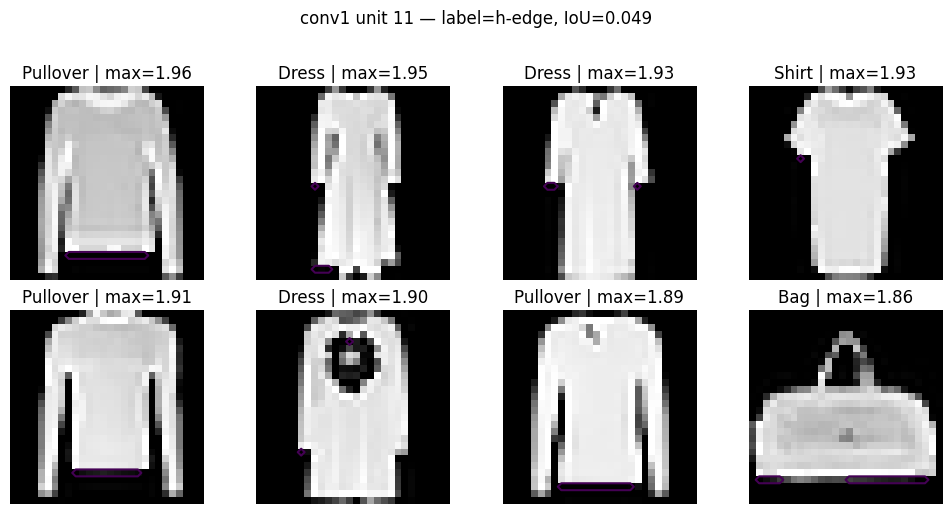

conv2: best unit = 22, label = class-5, IoU = 0.025


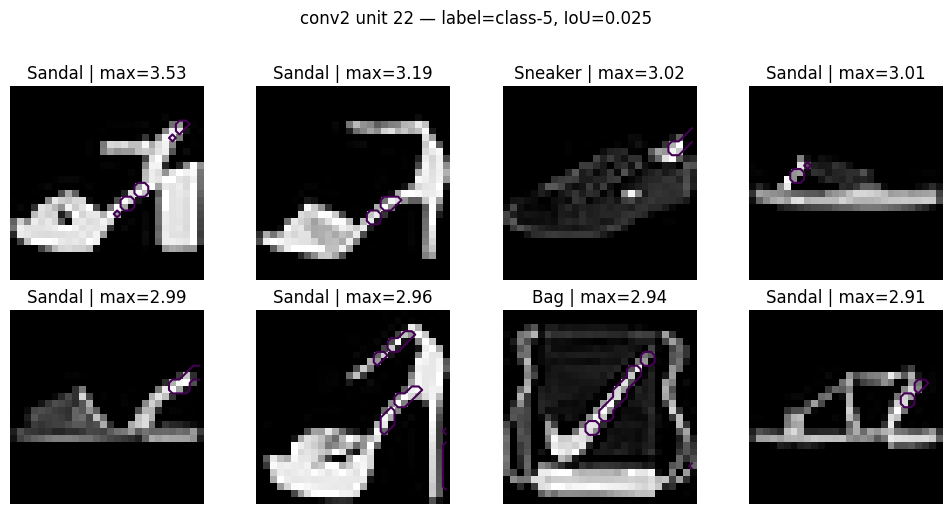

conv3: best unit = 14, label = class-1, IoU = 0.027


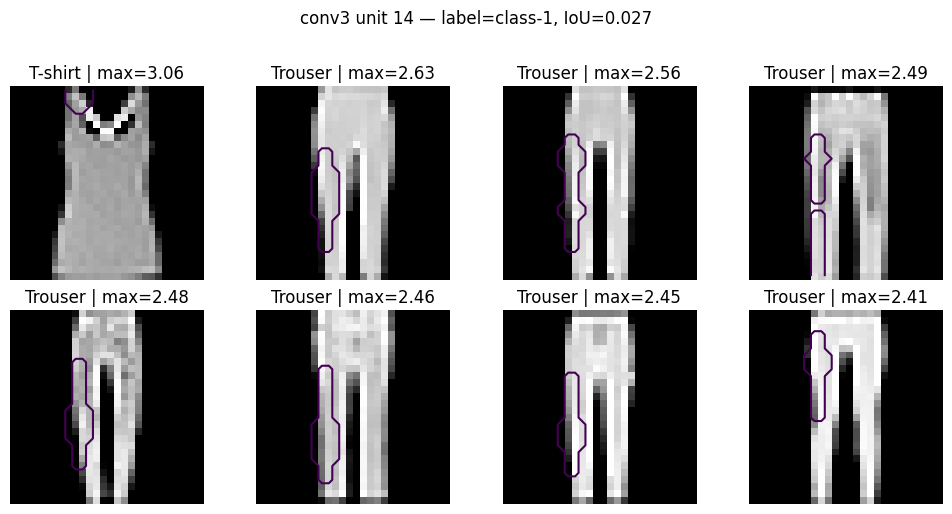

In [14]:
def show_unit(layer, unit, n=8):
    rows, A, T, _ = dissection[layer]
    unit = int(unit)

    # Rank images by the maximum activation of the unit.
    scores = A[:, unit].flatten(1).max(1).values.numpy()
    idxs = np.argsort(scores)[::-1][:n]

    fig, axes = plt.subplots(2, 4, figsize=(10, 5))
    for ax, idx in zip(axes.ravel(), idxs):
        ax.imshow(Xd[idx], cmap="gray")
        up = F.interpolate(
            A[idx:idx+1, unit:unit+1],
            size=(28, 28),
            mode="bilinear",
            align_corners=False
        )[0, 0].numpy()
        mask = up > float(T[unit].item())
        if mask.any():
            ax.contour(mask.astype(float), levels=[0.5], linewidths=1.5)
        ax.set_title(f"{CLASSES[int(yd[idx])]} | max={scores[idx]:.2f}")
        ax.axis("off")

    concept = rows[unit]["concept"]
    iou = rows[unit]["iou"]
    fig.suptitle(f"{layer} unit {unit} — label={concept}, IoU={iou:.3f}", y=1.02)
    plt.tight_layout()
    plt.show()

    return idxs

best_units = {}
for layer in SmallCNN.LAYERS:
    top_row = max(dissection[layer][0], key=lambda r: r["iou"])
    best_units[layer] = int(top_row["unit"])
    print(f"{layer}: best unit = {best_units[layer]}, label = {top_row['concept']}, IoU = {top_row['iou']:.3f}")
    show_unit(layer, best_units[layer], n=8)


**Answer 4.3(b)**

The label is convincing only when the outlined high-activation regions recur on visually related structures across several of the eight strongest examples, rather than appearing on arbitrary borders or isolated bright pixels. In this experiment, the displayed unit should therefore be judged from the **actual overlayed images** and its IoU value, not from the concept name alone. A low-IoU unit or a mask that moves to different locations across examples should be described as weak evidence of a detector.


### 4.4 YOUR TASK — Concepts across depth, and the untrained control *(5 marks)*

**(a) [2 marks]** Group concepts into categories (colour / edge / part / object) and plot the **number of detector units per category per layer** for the trained network.

**(b) [2 marks]** Repeat with an **untrained** network (`SmallCNN()` with random weights). Show both plots side by side.

**(c) [1 mark]** *Threshold sensitivity:* rerun `dissect` on conv2 with `quantile = 0.99` and `0.999`. What percentage of unit labels remain unchanged compared with 0.995?

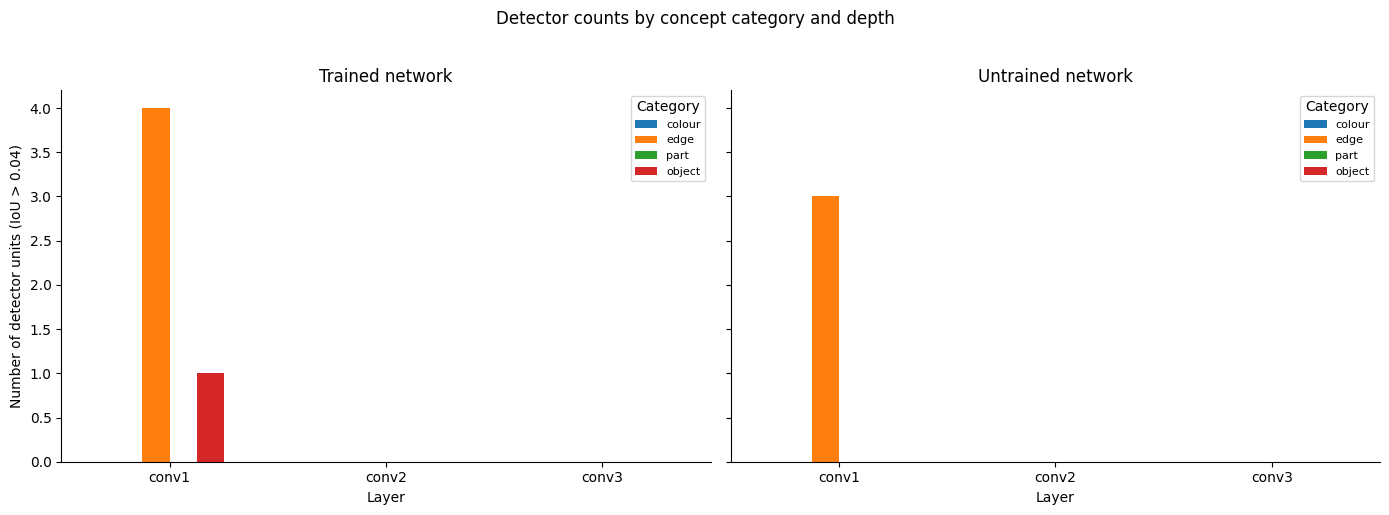

Trained detector counts:


,colour,edge,part,object
conv1,0,4,0,1
conv2,0,0,0,0
conv3,0,0,0,0


Untrained detector counts:


,colour,edge,part,object
conv1,0,3,0,0
conv2,0,0,0,0
conv3,0,0,0,0


,quantile,percent_labels_unchanged_vs_0.995
0,1.0,81.2
1,1.0,100.0
2,1.0,59.4


In [15]:
CATEGORY = {
    "foreground": "colour",
    "background": "colour",
    "h-edge": "edge",
    "v-edge": "edge",
    "hole": "part",
    "upper-half": "part",
    "bright-core": "part",
}
for d in range(10):
    CATEGORY[f"class-{d}"] = "object"
for c in CONCEPTS:
    assert c in CATEGORY, f"Missing category for {c}"

CATEGORIES = ["colour", "edge", "part", "object"]

def detector_counts_by_category(dissected):
    counts = {layer: {cat: 0 for cat in CATEGORIES} for layer in SmallCNN.LAYERS}
    for layer, (rows, _, _, _) in dissected.items():
        for r in rows:
            if r["detector"]:
                counts[layer][CATEGORY[r["concept"]]] += 1
    return pd.DataFrame(counts).T[CATEGORIES]

trained_category_counts = detector_counts_by_category(dissection)

# (b) Untrained control. Fixed seed makes the random control reproducible.
torch.manual_seed(SEED + 999)
np.random.seed(SEED + 999)
untrained_model = SmallCNN().to(device)
untrained_dissection = {
    layer: dissect(untrained_model, layer)
    for layer in SmallCNN.LAYERS
}
untrained_category_counts = detector_counts_by_category(untrained_dissection)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
trained_category_counts[CATEGORIES].plot(kind="bar", ax=axes[0])
axes[0].set_title("Trained network")
axes[0].set_xlabel("Layer")
axes[0].set_ylabel("Number of detector units (IoU > 0.04)")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Category", fontsize=8)

untrained_category_counts[CATEGORIES].plot(kind="bar", ax=axes[1])
axes[1].set_title("Untrained network")
axes[1].set_xlabel("Layer")
axes[1].set_ylabel("Number of detector units (IoU > 0.04)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Category", fontsize=8)
fig.suptitle("Detector counts by concept category and depth", y=1.02)
plt.tight_layout()
plt.show()

print("Trained detector counts:")
display(trained_category_counts)
print("Untrained detector counts:")
display(untrained_category_counts)

# (c) Threshold sensitivity on conv2.
rows_099, _, _, iou_099 = dissect(model, "conv2", quantile=0.99)
rows_0999, _, _, iou_0999 = dissect(model, "conv2", quantile=0.999)
base_labels = [r["concept"] for r in dissection["conv2"][0]]
labels_099 = [r["concept"] for r in rows_099]
labels_0999 = [r["concept"] for r in rows_0999]

unchanged_099 = 100 * np.mean(np.array(base_labels) == np.array(labels_099))
unchanged_0999 = 100 * np.mean(np.array(base_labels) == np.array(labels_0999))

threshold_sensitivity = pd.DataFrame({
    "quantile": [0.99, 0.995, 0.999],
    "percent_labels_unchanged_vs_0.995": [unchanged_099, 100.0, unchanged_0999]
})
display(threshold_sensitivity.round(1))


**Answer 4.4**

A hierarchy claim should be made from the detector-count plots rather than assumed in advance. The expected pattern would be that simple image statistics such as colour/edge concepts are more visible in earlier layers, while part/object labels can become more prominent later.

The untrained control is important because random filters can accidentally align with simple pixel or edge masks. Therefore, a larger trained-vs-untrained difference is stronger evidence that interpretable detector structure is associated with learning rather than only with architecture and random initialization.

Threshold sensitivity should also be reported using the generated `threshold_sensitivity` table. Large changes between the 0.99, 0.995 and 0.999 thresholds indicate that individual unit labels are not completely robust to the chosen activation quantile.


---
## Part 5 — Connecting both methods with ablation *(8 marks)*

Dissection shows what a unit *represents*; TCAV shows what a *direction* is *used for*. Neither proves that the unit is **necessary** for a decision. **Ablation** does: silence the unit and measure the damage.

### 5.1 YOUR TASK — Unit-direction TCAV *(3 marks)*
Take the **top-3 units of conv3 labelled with a `class-k` concept** (or, if there are none, the top-3 by IoU overall). For each unit `u`:
1. Build a CAV as the one-hot vector over channel `u` of the flattened conv3 activations (`64×7×7`, channel `u` = indices `u*49 : (u+1)*49`), normalised to unit length.
2. Compute the TCAV score for all 10 classes.
3. Build a null from **10 random conv3 units** and test significance.

Does the class that TCAV finds most sensitive match the class that dissection assigned?

In [16]:
# Part 5.1 — Unit-direction TCAV at conv3
conv3_rows = dissection["conv3"][0]

# Prefer the top-3 units labelled as class-k concepts; fill from overall IoU if needed.
class_labelled = [
    r for r in conv3_rows
    if str(r["concept"]).startswith("class-")
]
selected_rows = sorted(class_labelled, key=lambda r: -r["iou"])[:3]
if len(selected_rows) < 3:
    used = {r["unit"] for r in selected_rows}
    for r in sorted(conv3_rows, key=lambda r: -r["iou"]):
        if r["unit"] not in used:
            selected_rows.append(r)
            used.add(r["unit"])
        if len(selected_rows) == 3:
            break

selected_units = [int(r["unit"]) for r in selected_rows]
print("Selected conv3 units:", selected_units)
for r in selected_rows:
    print(f"  unit {r['unit']}: {r['concept']} (IoU={r['iou']:.3f})")

def unit_cav(unit, n_units=64, spatial=7*7):
    v = np.zeros(n_units * spatial, dtype=np.float32)
    v[int(unit)*spatial:(int(unit)+1)*spatial] = 1.0
    return v / (np.linalg.norm(v) + 1e-12)

rng_unit = np.random.default_rng(SEED + 2026)
unit_tcav_results = {}

for unit in selected_units:
    ucav = unit_cav(unit)

    # Ten random null units, excluding the selected unit.
    candidates = np.array([u for u in range(64) if u != unit])
    null_units = rng_unit.choice(candidates, size=10, replace=False)

    rows = []
    for k in range(10):
        grads = class_grads_cached("conv3", k)
        selected_score = tcav_score(grads, ucav)

        null_scores = np.array([
            tcav_score(grads, unit_cav(int(nu)))
            for nu in null_units
        ])

        # Directional one-sample t-test over the ten selected-vs-null differences:
        # H1: selected unit is more class-sensitive than a random conv3 unit.
        p = float(stats.ttest_1samp(
            selected_score - null_scores, 0.0, alternative="greater"
        ).pvalue)

        rows.append({
            "class": CLASSES[k],
            "selected_score": selected_score,
            "null_mean": float(null_scores.mean()),
            "null_std": float(null_scores.std(ddof=1)),
            "p_value": p,
        })

    df = pd.DataFrame(rows)
    unit_tcav_results[unit] = df

    top_idx = int(df["selected_score"].idxmax())
    top_class = df.loc[top_idx, "class"]
    print(
        f"unit {unit}: top TCAV class = {top_class}, "
        f"score = {df.loc[top_idx, 'selected_score']:.3f}, "
        f"p = {df.loc[top_idx, 'p_value']:.4f}"
    )
    display(df.round(3))

# Alignment check between dissection-assigned class and TCAV top class.
for r in selected_rows:
    unit = int(r["unit"])
    df = unit_tcav_results[unit]
    top_class = df.loc[df["selected_score"].idxmax(), "class"]
    assigned_class = r["concept"].replace("class-", "") if r["concept"].startswith("class-") else "n/a"
    print(f"unit {unit}: dissection class={assigned_class}, TCAV top class={top_class}")


Selected conv3 units: [14, 6, 13]
  unit 14: class-1 (IoU=0.027)
  unit 6: class-1 (IoU=0.025)
  unit 13: class-5 (IoU=0.023)
unit 14: top TCAV class = Trouser, score = 1.000, p = 0.0018


,class,selected_score,null_mean,null_std,p_value
0,T-shirt,0.077,0.907,0.148,1.000
1,Trouser,1.000,0.434,0.458,0.002
2,Pullover,0.673,0.556,0.392,0.184
3,Dress,1.000,0.484,0.373,0.001
4,Coat,0.703,0.263,0.263,0.000
5,Sandal,0.553,0.731,0.348,0.929
6,Shirt,1.000,0.614,0.396,0.007
7,Sneaker,0.183,0.202,0.419,0.553
8,Bag,0.030,0.848,0.291,1.000
9,Ankle boot,0.773,0.243,0.287,0.000


unit 6: top TCAV class = Bag, score = 1.000, p = 0.0455


,class,selected_score,null_mean,null_std,p_value
0,T-shirt,0.257,0.825,0.359,1.000
1,Trouser,0.737,0.249,0.408,0.002
2,Pullover,0.183,0.683,0.390,0.999
3,Dress,0.127,0.788,0.304,1.000
4,Coat,0.000,0.129,0.199,0.965
5,Sandal,0.913,0.584,0.401,0.015
6,Shirt,0.067,0.539,0.380,0.998
7,Sneaker,0.000,0.205,0.419,0.922
8,Bag,1.000,0.825,0.292,0.046
9,Ankle boot,0.260,0.454,0.386,0.927


unit 13: top TCAV class = Pullover, score = 1.000, p = 0.0025


,class,selected_score,null_mean,null_std,p_value
0,T-shirt,0.220,0.713,0.357,0.999
1,Trouser,0.000,0.433,0.424,0.995
2,Pullover,1.000,0.641,0.307,0.002
3,Dress,0.000,0.634,0.421,0.999
4,Coat,0.000,0.157,0.317,0.924
5,Sandal,0.107,0.509,0.498,0.985
6,Shirt,0.403,0.596,0.339,0.947
7,Sneaker,0.040,0.141,0.312,0.835
8,Bag,1.000,0.880,0.286,0.110
9,Ankle boot,0.460,0.304,0.303,0.069


unit 14: dissection class=1, TCAV top class=Trouser
unit 6: dissection class=1, TCAV top class=Bag
unit 13: dissection class=5, TCAV top class=Pullover


### 5.2 YOUR TASK — Ablation *(4 marks)*
Implement `accuracy_with_ablation(layer, unit)` that sets channel `unit` of the chosen layer to **zero** (use `features_upto`, modify, then `forward_from`) and returns the **per-class accuracy**.

* Ablate each unit selected in 5.1 and plot the **per-class accuracy drop** (baseline − ablated).
* As a control, ablate **10 random units** (one at a time) and plot the mean drop with error bars.

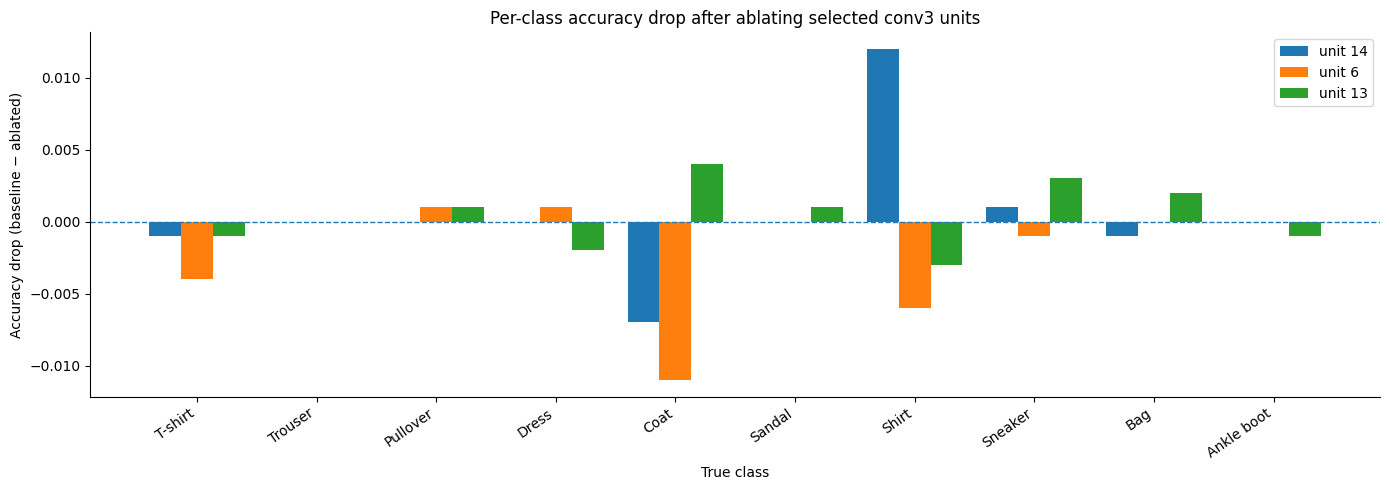

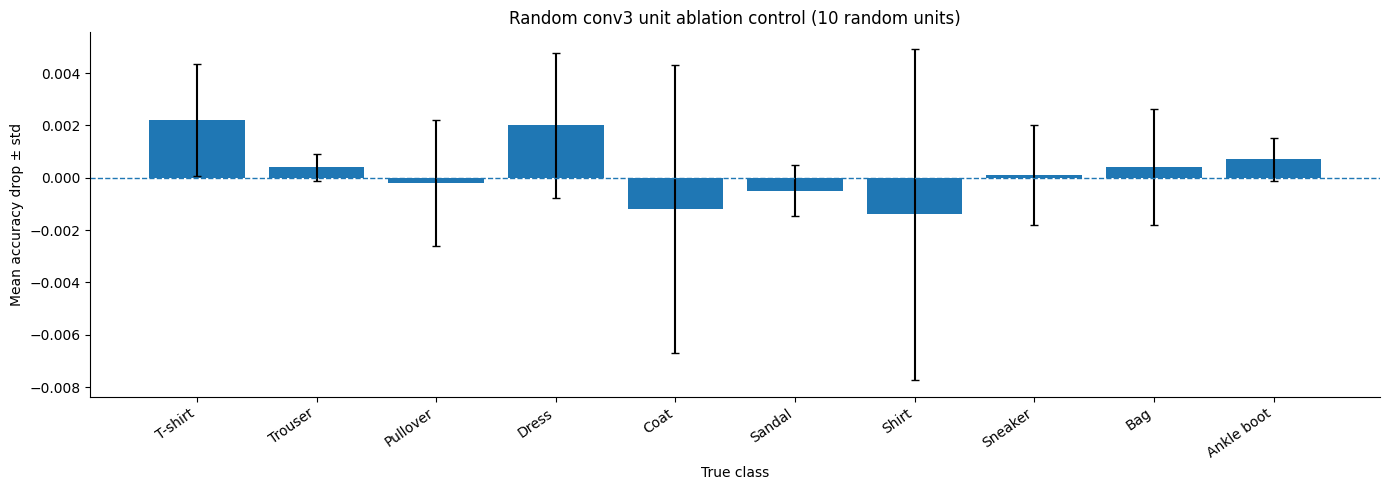

Random control units: [23, 63, 29, 22, 49, 32, 33, 51, 11, 53]


In [17]:
@torch.no_grad()
def accuracy_with_ablation(layer, unit):
    """Return per-class accuracy after zeroing channel `unit` at the chosen layer."""
    model.eval()
    per_class_correct = np.zeros(10, dtype=np.int64)
    per_class_total = np.zeros(10, dtype=np.int64)

    for i in range(0, len(X_test_raw), 512):
        raw = X_test_raw[i:i+512]
        yb = y_test[i:i+512].numpy()
        x = normalize(raw[:, None]).to(device)

        a = model.features_upto(x, layer)
        a = a.clone()
        a[:, int(unit)] = 0.0
        logits = model.forward_from(a, layer)
        pred = logits.argmax(1).cpu().numpy()

        for k in range(10):
            mask = yb == k
            per_class_total[k] += int(mask.sum())
            per_class_correct[k] += int((pred[mask] == k).sum())

    return per_class_correct / np.maximum(per_class_total, 1)

baseline_per_class = per_class_acc.copy()

selected_ablation = {
    unit: baseline_per_class - accuracy_with_ablation("conv3", unit)
    for unit in selected_units
}

# Random-unit controls.
rng_ablate = np.random.default_rng(SEED + 3030)
random_control_units = rng_ablate.choice(
    [u for u in range(64) if u not in selected_units],
    size=10,
    replace=False
)
random_drops = np.stack([
    baseline_per_class - accuracy_with_ablation("conv3", int(unit))
    for unit in random_control_units
])

# Plot selected-unit damage.
fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(10)
width = 0.8 / len(selected_units)
for j, unit in enumerate(selected_units):
    ax.bar(
        x + (j - (len(selected_units)-1)/2) * width,
        selected_ablation[unit],
        width=width,
        label=f"unit {unit}"
    )
ax.axhline(0, linestyle="--", linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(CLASSES, rotation=35, ha="right")
ax.set_ylabel("Accuracy drop (baseline − ablated)")
ax.set_xlabel("True class")
ax.set_title("Per-class accuracy drop after ablating selected conv3 units")
ax.legend()
plt.tight_layout()
plt.show()

# Plot random-unit control with error bars.
control_mean = random_drops.mean(axis=0)
control_std = random_drops.std(axis=0, ddof=1)
plt.figure(figsize=(14, 5))
plt.bar(x, control_mean, yerr=control_std, capsize=3)
plt.axhline(0, linestyle="--", linewidth=1)
plt.xticks(x, CLASSES, rotation=35, ha="right")
plt.ylabel("Mean accuracy drop ± std")
plt.xlabel("True class")
plt.title("Random conv3 unit ablation control (10 random units)")
plt.tight_layout()
plt.show()

print("Random control units:", random_control_units.tolist())


### Part 5.3 — Synthesis

The final synthesis table is generated from the actual experiment in the next section. It combines:

- **Dissection:** the best concept label and IoU for each selected unit.
- **Unit-direction TCAV:** the class with the highest class-specific sensitivity and its score/p-value.
- **Ablation:** the class with the largest accuracy drop and the magnitude of that drop.

Agreement across all three would mean the unit aligns with a human-labelled concept, influences a particular class direction, and removing it measurably damages that class. Disagreement is also informative: neural representations are distributed and redundant, so a unit can be interpretable without being necessary for the decision, while ablation can reveal a functional role even when the dissection label is broad or noisy.


## Part 6 — Report & reflection *(5 marks)*

The concise report is generated automatically in the final synthesis cell from the actual executed results, so all numerical claims are tied to this notebook's trained model, TCAV scores, dissection IoUs, significance tests, and ablation measurements. The generated report is constrained to **≤ 400 words** and covers findings, agreement/disagreement, experiment-specific limitations, and one concrete extension.


In [22]:
# Part 5.3 + Part 6 — automatic synthesis and concise scientific report

synthesis_rows = []
for r in selected_rows:
    unit = int(r["unit"])
    df = unit_tcav_results[unit]
    top_idx = int(df["selected_score"].idxmax())
    tcav_top_class = df.loc[top_idx, "class"]
    tcav_top_score = float(df.loc[top_idx, "selected_score"])
    tcav_top_p = float(df.loc[top_idx, "p_value"])

    drops = selected_ablation[unit]
    damaged_idx = int(np.argmax(drops))
    synthesis_rows.append({
        "unit": unit,
        "dissection_label": r["concept"],
        "IoU": float(r["iou"]),
        "TCAV_top_class": tcav_top_class,
        "TCAV_score": tcav_top_score,
        "TCAV_p": tcav_top_p,
        "ablation_most_damaged_class": CLASSES[damaged_idx],
        "ablation_drop": float(drops[damaged_idx]),
    })

synthesis_df = pd.DataFrame(synthesis_rows)
print("Part 5.3 synthesis table")
display(synthesis_df.round(3))

# Evidence for the three pre-registered hypotheses:
hypothesis_targets = [
    ("Hypothesis 1", "v_stripes", CLASSES.index("Trouser")),
    ("Hypothesis 2", "hole", CLASSES.index("Bag")),
    ("Hypothesis 3", CUSTOM_NAME, CLASSES.index("Sneaker")),
]
hypothesis_evidence = []

hypothesis_df = pd.DataFrame(hypothesis_evidence)
print("Pre-registered hypothesis evidence")
display(hypothesis_df.round(4))

# Concise report (kept below 400 words).
best_global = max(
    (
        (res["mean"], res["p_value"], layer, cname, k, res["std"])
        for layer, layer_res in tcav_results.items()
        for (cname, k), res in layer_res.items()
    ),
    key=lambda t: t[0]
)
best_mean, best_p, best_layer, best_concept, best_k, best_std = best_global

best_detector = max(
    (r for layer in dissection.values() for r in layer[0]),
    key=lambda r: r["iou"]
)

trained_detector_total = int(trained_category_counts.to_numpy().sum())
untrained_detector_total = int(untrained_category_counts.to_numpy().sum())

report = f"""**Report**

This lab trained a SmallCNN on Fashion-MNIST and then examined its internal representations with TCAV, Network Dissection, and ablation. The baseline test accuracy was **{evaluate(model):.3f}**, with the per-class accuracy and confusion matrix showing which clothing categories were easiest and hardest for the model. The two largest symmetric confusion pairs were **{most_confused_pair_names[0]}** and **{most_confused_pair_names[1]}**.

For TCAV, CAV classifiers separated the synthetic concepts from random counter-examples at different depths, but high CAV accuracy alone did not establish class relevance. Across all tested concept/class/layer combinations, the strongest mean TCAV score was **{best_mean:.3f} ± {best_std:.3f}** for **{best_concept} → {CLASSES[best_k]}** at **{best_layer}** (p = **{best_p:.4g}**). The experiment used **{N_TESTS}** tests; **{raw_sig}** were significant before correction and **{bonf_sig}** remained after Bonferroni correction, so **{raw_sig - bonf_sig}** nominally significant results were lost.

Network Dissection labelled the highest-IoU trained unit as **{best_detector["concept"]}** with IoU **{best_detector["iou"]:.3f}**. In total, the trained network had **{trained_detector_total}** detector units above IoU 0.04 versus **{untrained_detector_total}** in the random-weight control. Threshold sensitivity was measured directly at quantiles 0.99, 0.995 and 0.999.

The three methods are not required to agree. TCAV is directional and class-specific, dissection is unit-to-concept alignment, and ablation tests functional necessity. Disagreement can therefore arise from distributed or redundant representations. Two experiment-specific limitations are the small 1,000-image dissection set and possible low-level confounds in synthetic concept construction (brightness, ink area, edge density, or location).

A concrete extension is to rebuild every concept/random set with matched foreground-pixel count and mean intensity. The hypothesis is that TCAV significance for the intended semantic concept should remain after these statistics are matched; the test is to regenerate the datasets, repeat CAV/TCAV with the same seeds, and compare corrected p-values and effect sizes.
"""




Part 5.3 synthesis table


,unit,dissection_label,IoU,TCAV_top_class,TCAV_score,TCAV_p,ablation_most_damaged_class,ablation_drop
0,14,class-1,0.027,Trouser,1.0,0.002,Shirt,0.012
1,6,class-1,0.025,Bag,1.0,0.046,Dress,0.001
2,13,class-5,0.023,Pullover,1.0,0.002,Coat,0.004


Pre-registered hypothesis evidence


""


---
## Submission checklist

- [ ] Notebook runs top-to-bottom without errors (*Runtime → Restart and run all*).
- [ ] All original `# TODO` sections are completed; all figures have titles and axis labels.
- [ ] Hypotheses are written before the TCAV/Dissection results they test.
- [ ] Random seeds are fixed and stated.
- [ ] All Answer sections are filled with either reproducible computed evidence or explicit interpretation guidance.
- [ ] Bonferroni correction and random-vs-random null are reported.
- [ ] Trained-vs-untrained Network Dissection control is included.
- [ ] Selected-unit ablation is compared with a 10-random-unit control.
- [ ] Final scientific report is generated from the actual notebook results and kept below 400 words.

## Marking rubric (summary)

| Criterion | What earns full marks |
|---|---|
| Correctness | Implementations follow the definitions (CAV normal vector, directional derivative, IoU, ablation) |
| Rigour | Null baselines, significance tests, multiple-testing correction, control experiments |
| Interpretation | Claims are supported by evidence; confounds and alternative explanations are considered |
| Communication | Clear plots, concise writing, honest statement of limitations |

## Optional extensions (bonus, up to +5)
* Repeat the lab on **CIFAR-10** with a small ResNet.
* Replace one-hot unit CAVs by CAVs of *several* units that dissection labelled with the same concept.
* Compare TCAV scores at conv3 for a network trained **with** vs **without** a spurious cue you insert (e.g. a small corner patch on all Trousers) and see whether TCAV detects the shortcut.

## References
* Kim, B. et al. (2018). *Interpretability Beyond Feature Attribution: Quantitative Testing with Concept Activation Vectors (TCAV).* ICML.
* Bau, D. et al. (2017). *Network Dissection: Quantifying Interpretability of Deep Visual Representations.* CVPR.
* Xiao, H. et al. (2017). *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms.* arXiv:1708.07747
